# 05 — Oráculos: Deutsch, Deutsch-Jozsa, Bernstein-Vazirani y Simon

**Curso ECCI 2026 · Computación cuántica**

Los cuatro algoritmos de este notebook son una **escalera**. Cada escalón
usa
el mismo par de trucos que el anterior, y saca más información:

| algoritmo | qué pregunta | consultas clásicas | consultas cuánticas |
|---|---|---|---|
| **Deutsch** | ¿$f$ es constante o balanceada? (1 bit de entrada) | 2 | **1** |
| **Deutsch-Jozsa** | lo mismo, con $n$ bits | $2^{n-1}+1$ (determinista) | **1** |
| **Bernstein-Vazirani** | ¿cuál es la cadena oculta $s$? ($n$ bits de salida) | $n$ | **1** |
| **Simon** | ¿cuál es la máscara oculta $s$ con $f(x)=f(x\oplus s)$? | $O(2^{n/2})$ | **$O(n)$** |

Y los dos trucos son siempre los mismos:

1. **Retroceso de fase**: el oráculo escribe su respuesta en una *fase*, no
en
   un bit. (El mismo mecanismo de QPE, `08`.)
2. **Transformada de Hadamard**: $H^{\otimes n}$ convierte ese patrón de
fases
   en un patrón de amplitudes que se puede medir.

Los tres primeros son *juguetes*: problemas inventados para que la ventaja
se
vea. **Simon no**: su separación es exponencial incluso contra algoritmos
clásicos aleatorizados, y fue el que le dio a Shor la idea de buscar
períodos.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_state_qsphere
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. El modelo de oráculo

En todos estos problemas hay una función $f$ que se puede **evaluar** pero
no
**inspeccionar**. Se cuenta cuántas evaluaciones hacen falta: eso es la
*complejidad de consulta*, y es el único escenario donde se pueden demostrar
separaciones exactas entre lo clásico y lo cuántico.

Para que sea reversible, el oráculo cuántico se define como

$$U_f\,|x\rangle|y\rangle = |x\rangle\,|y \oplus f(x)\rangle .$$

### El truco del qubit auxiliar en $|-\rangle$

Poner el registro de salida en $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$:

$$U_f|x\rangle|-\rangle
 = |x\rangle \frac{|f(x)\rangle - |1 \oplus f(x)\rangle}{\sqrt2}
 = (-1)^{f(x)}\,|x\rangle|-\rangle .$$

Si $f(x) = 0$ el auxiliar queda igual; si $f(x) = 1$, los dos términos se
intercambian y aparece un signo menos. El auxiliar **nunca cambia**, y la
respuesta de $f$ se escribió como una fase sobre $|x\rangle$.

Eso es el retroceso de fase, y es lo que permite consultar $f$ sobre **todos
los $x$ a la vez**: si el registro de entrada está en superposición
uniforme,
una sola llamada produce

$$\frac{1}{\sqrt{2^n}}\sum_x (-1)^{f(x)}|x\rangle .$$

Una advertencia: eso **no** es "calcular $f$ en paralelo y quedarse con
todo". Al medir sale un solo $x$, con probabilidad $1/2^n$, y la fase ni se
ve. Los algoritmos que siguen son recetas para que esas fases
**interfieran**
de modo que la propiedad global buscada aparezca en las amplitudes.

---
# 2. Deutsch: un bit, una consulta

$f: \{0,1\} \to \{0,1\}$. Hay cuatro funciones posibles: dos **constantes**
($f \equiv 0$, $f \equiv 1$) y dos **balanceadas** ($f = x$, $f = \bar x$).
La pregunta es si $f$ es constante o balanceada — el valor de $f(0) \oplus
f(1)$ — y no cuánto vale en cada punto.

Clásicamente hacen falta **dos** consultas: sabiendo solo $f(0)$ no se puede
decir nada. Cuánticamente, **una**.

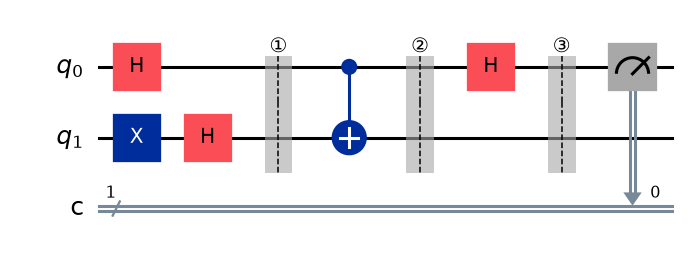


f                   resultado  interpretación
constante_0                 0  constante
constante_1                 0  constante
balanceada_id               1  balanceada
balanceada_not              1  balanceada


In [4]:
def oraculo_deutsch(tipo: str) -> QuantumCircuit:
    """Los cuatro f posibles, como circuito sobre |x>|y>."""
    qc = QuantumCircuit(2, name=f"f={tipo}")
    if tipo == "constante_1":
        qc.x(1)
    elif tipo == "balanceada_id":      # f(x) = x
        qc.cx(0, 1)
    elif tipo == "balanceada_not":     # f(x) = 1 - x
        qc.cx(0, 1)
        qc.x(1)
    return qc                          # "constante_0" no hace nada


def deutsch(tipo: str) -> QuantumCircuit:
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h([0, 1])                       # entrada en |+>, auxiliar en |->
    marca(qc, 1)
    qc.compose(oraculo_deutsch(tipo), range(2), inplace=True)
    marca(qc, 2)
    qc.h(0)
    marca(qc, 3)
    qc.measure(0, 0)
    return qc


tipos = ["constante_0", "constante_1", "balanceada_id", "balanceada_not"]
c_deutsch = utils.correr_ideal([deutsch(t) for t in tipos], shots=2048)

display(deutsch("balanceada_id").draw("mpl", style="iqp"))
print(f"\n{'f':<18} {'resultado':>10}  interpretación")
for t, c in zip(tipos, c_deutsch):
    r = max(c, key=c.get)
    print(f"{t:<18} {r:>10}  {'constante' if r == '0' else 'balanceada'}")

### La cuenta

**①** Dado que se aplica $X$ al auxiliar y $H$ a los dos:
$$|\psi_1\rangle = |+\rangle\,|-\rangle
 = \frac{|0\rangle + |1\rangle}{\sqrt2}\,|-\rangle .$$

**②** Dado que se aplica $U_f$, que por el truco del $|-\rangle$ escribe la
respuesta como fase:
$$|\psi_2\rangle = \frac{(-1)^{f(0)}|0\rangle + (-1)^{f(1)}|1\rangle}{\sqrt2}\,|-\rangle
 = (-1)^{f(0)}\,\frac{|0\rangle + (-1)^{f(0)\oplus
   f(1)}|1\rangle}{\sqrt2}\,|-\rangle .$$
Sacando la fase global, **el estado depende solo de $f(0) \oplus f(1)$**: es
$|+\rangle$ si $f$ es constante y $|-\rangle$ si es balanceada. Las dos
consultas clásicas se hicieron en una porque el estado quedó en función de
su XOR, sin que se calculara ninguno de los dos valores por separado.

**③** Dado que se aplica $H$, que manda $|+\rangle \to |0\rangle$ y
$|-\rangle \to |1\rangle$: medir da **0 si es constante, 1 si es
balanceada**,
con certeza.

La $H$ final es lo esencial: $|+\rangle$ y $|-\rangle$ son indistinguibles
al
medir en $Z$ (los dos dan 50/50), y la $H$ los rota a una base donde sí se
distinguen. Es la misma maniobra del Stern-Gerlach del `01b`.

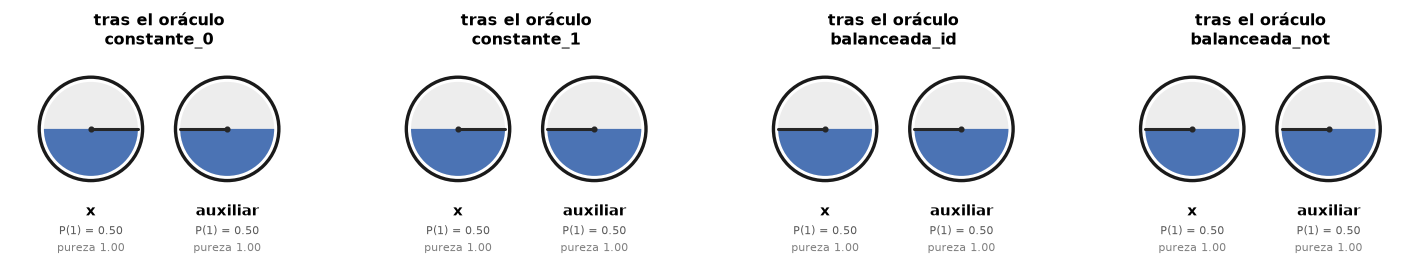

La aguja del qubit x apunta a 0° (constante) o a 180° (balanceada).
El auxiliar no cambió en ningún caso: sigue en |−⟩, aguja a 180°.


In [5]:
fig, ejes = plt.subplots(1, 4, figsize=(13.5, 2.5))
for ax, t in zip(ejes, tipos):
    qc = QuantumCircuit(2)
    qc.x(1); qc.h([0, 1])
    qc.compose(oraculo_deutsch(t), range(2), inplace=True)
    utils.discos_qubits(Statevector(qc), ax=ax, etiquetas=["x", "auxiliar"],
                        titulo=f"tras el oráculo\n{t}")
utils.layout(fig)
plt.show()
print("La aguja del qubit x apunta a 0° (constante) o a 180° (balanceada).")
print("El auxiliar no cambió en ningún caso: sigue en |−⟩, aguja a 180°.")

---
# 3. Deutsch-Jozsa: lo mismo, con $n$ bits

Ahora $f: \{0,1\}^n \to \{0,1\}$, con la **promesa** de que es constante o
exactamente balanceada (mitad ceros, mitad unos). Nada intermedio.

Clásicamente, en el **peor caso** hay que mirar $2^{n-1}+1$ entradas: si las
primeras $2^{n-1}$ dieron todas 0, todavía puede ser constante o balanceada.
Cuánticamente alcanza una consulta.

El circuito es idéntico al de Deutsch, con $n$ qubits de entrada:

$$|0\rangle^{\otimes n}
\xrightarrow{H^{\otimes n}} \frac{1}{\sqrt{2^n}}\sum_x |x\rangle
\xrightarrow{U_f} \frac{1}{\sqrt{2^n}}\sum_x (-1)^{f(x)}|x\rangle
\xrightarrow{H^{\otimes n}} \ldots$$

La amplitud final de $|0\ldots0\rangle$ es

$$\frac{1}{2^n}\sum_x (-1)^{f(x)}
 = \begin{cases} \pm 1 & f \text{ constante}\\ 0 & f \text{
   balanceada}\end{cases}$$

**Si $f$ es constante, todos los términos suman en fase y el resultado es
`000…0` con probabilidad 1. Si es balanceada, se cancelan exactamente y
`000…0` tiene probabilidad cero.** Interferencia constructiva contra
destructiva, sin ningún término intermedio.

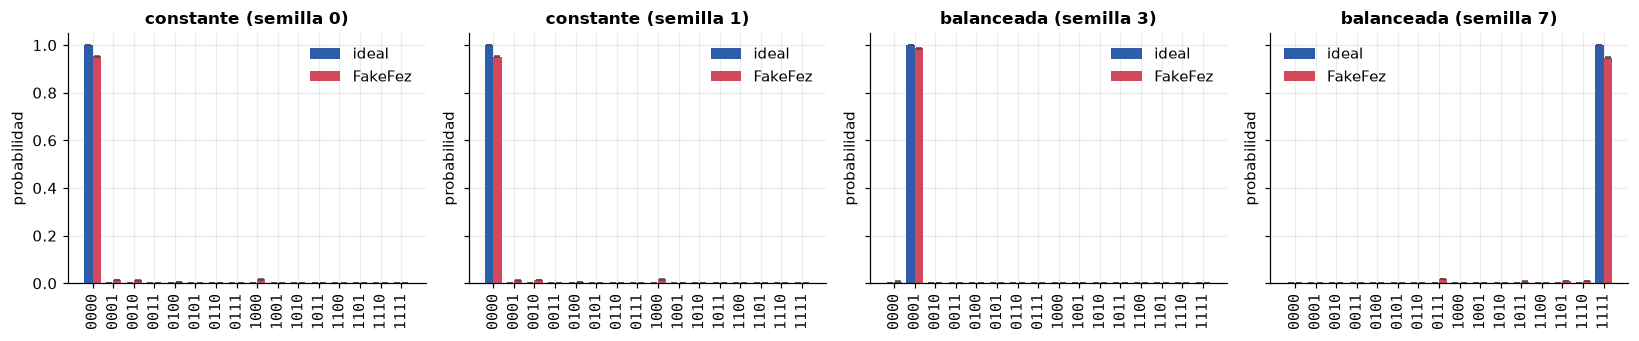

regla de decisión: '0000' ⟹ constante;  cualquier otra ⟹ balanceada

caso                    P(0000) ideal  P(0000) ruido  veredicto
constante 0                    1.0000         0.9532  constante
constante 1                    1.0000         0.9504  constante
balanceada 3                   0.0000         0.0071  balanceada
balanceada 7                   0.0000         0.0010  balanceada


In [6]:
def oraculo_dj(n: int, tipo: str, semilla=0) -> QuantumCircuit:
    """Oráculo de Deutsch-Jozsa sobre n+1 qubits."""
    qc = QuantumCircuit(n + 1, name=f"DJ {tipo}")
    if tipo == "constante":
        if semilla % 2:
            qc.x(n)
    else:
        # balanceada: f(x) = paridad de un subconjunto no vacío de bits
        rng = np.random.default_rng(semilla)
        subconjunto = [i for i in range(n) if rng.integers(2)] or [0]
        for i in subconjunto:
            qc.cx(i, n)
    return qc


def deutsch_jozsa(n: int, tipo: str, semilla=0) -> QuantumCircuit:
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    marca(qc, 1)
    qc.compose(oraculo_dj(n, tipo, semilla), range(n + 1), inplace=True)
    marca(qc, 2)
    qc.h(range(n))
    marca(qc, 3)
    qc.measure(range(n), range(n))
    return qc


N_DJ = 4
casos_dj = [("constante", 0), ("constante", 1), ("balanceada", 3), ("balanceada", 7)]
c_dj = utils.correr_ideal([deutsch_jozsa(N_DJ, t, s) for t, s in casos_dj], shots=SHOTS)
c_dj_r = utils.correr_ruidoso([deutsch_jozsa(N_DJ, t, s) for t, s in casos_dj],
                              backend_falso=fez, shots=SHOTS)

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (t, s), ci, cr in zip(ejes, casos_dj, c_dj, c_dj_r):
    utils.comparar_conteos({"ideal": ci, "FakeFez": cr},
                           claves=utils.claves_completas(N_DJ), ax=ax,
                           titulo=f"{t} (semilla {s})")
    ax.set_xlabel("")
utils.layout(fig)
plt.show()

print(f"regla de decisión: '{'0' * N_DJ}' ⟹ constante;  cualquier otra ⟹ balanceada\n")
print(f"{'caso':<22} {'P(0000) ideal':>14} {'P(0000) ruido':>14}  veredicto")
for (t, s), ci, cr in zip(casos_dj, c_dj, c_dj_r):
    p_i = ci.get("0" * N_DJ, 0) / SHOTS
    p_r = cr.get("0" * N_DJ, 0) / SHOTS
    print(f"{t + ' ' + str(s):<22} {p_i:>14.4f} {p_r:>14.4f}  "
          f"{'constante' if p_r > 0.5 else 'balanceada'}")

**La honestidad obliga a un asterisco.** La separación de Deutsch-Jozsa es
exponencial solo contra algoritmos **deterministas**. Si se acepta equivocarte
con probabilidad $10^{-9}$, un algoritmo clásico aleatorizado resuelve DJ
mirando **30 entradas al azar**, sin importar $n$: si aparecen dos valores
distintos es balanceada, y si las 30 coinciden es constante con altísima
probabilidad.

Así que DJ es una demostración de principio, no una ventaja práctica. Lo que
sí es real y transferible es el **mecanismo**: consultar en superposición,
escribir la respuesta en fases, e interferir. Eso reaparece en todo lo que
sigue.

---
# 4. Bernstein-Vazirani: $n$ bits en una consulta

Ahora la función es

$$f(x) = s \cdot x \bmod 2 = s_1x_1 \oplus s_2x_2 \oplus \cdots \oplus s_nx_n ,$$

con $s$ una cadena oculta de $n$ bits. **La pregunta ya no es un sí/no: es
`¿cuál es $s$?`**, o sea $n$ bits de respuesta.

Clásicamente hacen falta exactamente $n$ consultas: evaluando en
$x = 100\ldots0$ sale $s_1$, en $010\ldots0$ sale $s_2$, y así. Un bit por
consulta, y no hay forma de hacerlo mejor.

**Cuánticamente, una sola consulta devuelve $s$ entero.** Y el circuito es
*exactamente el mismo* que el de Deutsch-Jozsa: lo único que cambia es que
ahora leemos la cadena completa en vez de preguntar si es cero.

La cuenta: después del oráculo el estado es
$\frac{1}{\sqrt{2^n}}\sum_x (-1)^{s\cdot x}|x\rangle$, y ese es
**exactamente**
$H^{\otimes n}|s\rangle$. Aplicar $H^{\otimes n}$ otra vez —que es su propia
inversa— devuelve $|s\rangle$, con probabilidad 1.

Dicho de otro modo: el oráculo de BV *escribe $s$ en las fases*, y la
transformada de Hadamard lo *lee*.

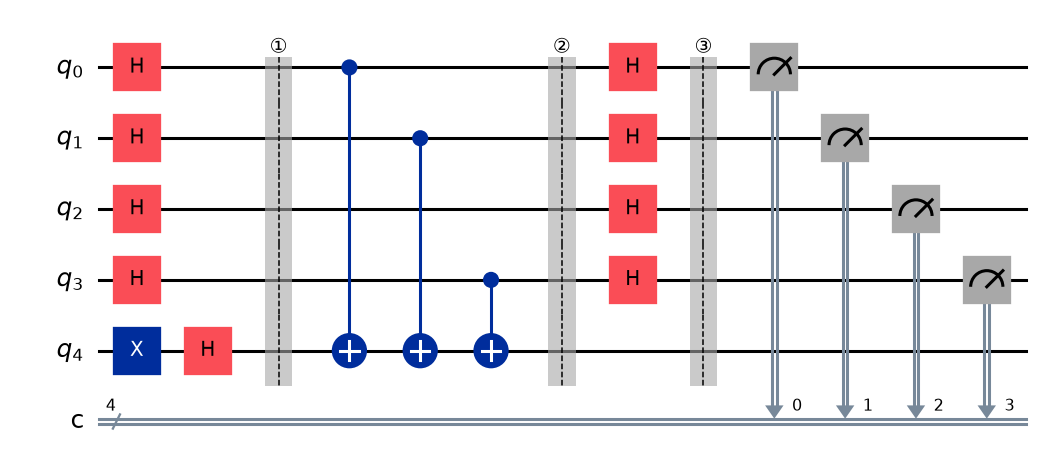

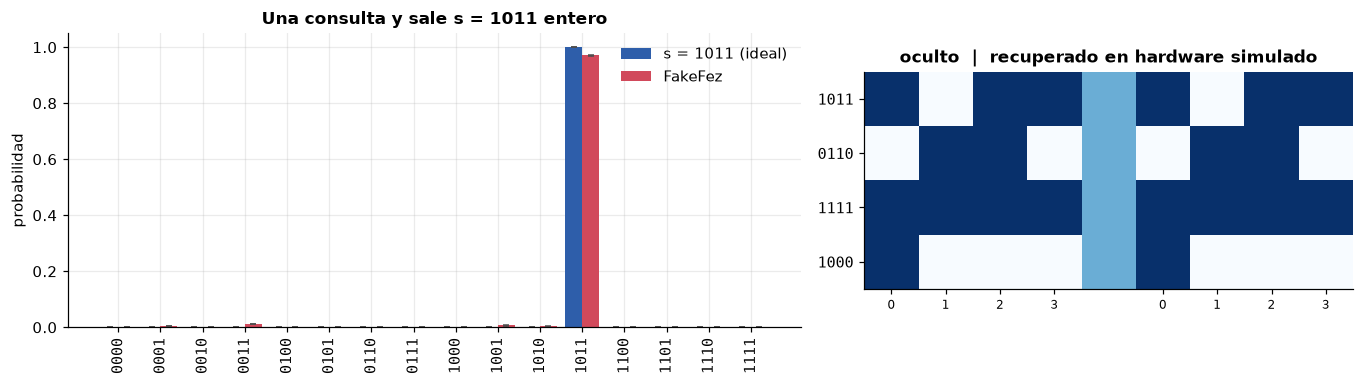

  s oculto   recuperado   P(s) ideal   P(s) FakeFez
      1011         1011       1.0000         0.9717
      0110         0110       1.0000         0.9756
      1111         1111       1.0000         0.9459
      1000         1000       1.0000         0.9520


In [7]:
def oraculo_bv(s: str) -> QuantumCircuit:
    """f(x) = s·x mod 2. Una CNOT por cada bit prendido de s."""
    n = len(s)
    qc = QuantumCircuit(n + 1, name=f"BV s={s}")
    for i, b in enumerate(s[::-1]):     # s[::-1] para que s[0] sea el qubit 0
        if b == "1":
            qc.cx(i, n)
    return qc


def bernstein_vazirani(s: str) -> QuantumCircuit:
    n = len(s)
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    marca(qc, 1)
    qc.compose(oraculo_bv(s), range(n + 1), inplace=True)
    marca(qc, 2)
    qc.h(range(n))
    marca(qc, 3)
    qc.measure(range(n), range(n))
    return qc


S_SECRETO = "1011"
display(bernstein_vazirani(S_SECRETO).draw("mpl", style="iqp", fold=-1))

secretos = ["1011", "0110", "1111", "1000"]
c_bv = utils.correr_ideal([bernstein_vazirani(s) for s in secretos], shots=SHOTS)
c_bv_r = utils.correr_ruidoso([bernstein_vazirani(s) for s in secretos],
                              backend_falso=fez, shots=SHOTS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6),
                               gridspec_kw={"width_ratios": [1.5, 1]})
utils.comparar_conteos({f"s = {secretos[0]} (ideal)": c_bv[0],
                        "FakeFez": c_bv_r[0]},
                       claves=utils.claves_completas(4), ax=ax1,
                       titulo=f"Una consulta y sale s = {secretos[0]} entero")

# bitmap: oculto vs recuperado
M = np.zeros((len(secretos), 2 * len(secretos[0]) + 1))
for i, s in enumerate(secretos):
    rec = max(c_bv_r[i], key=c_bv_r[i].get)
    for j, b in enumerate(s):
        M[i, j] = int(b)
    M[i, len(s)] = 0.5
    for j, b in enumerate(rec):
        M[i, len(s) + 1 + j] = int(b)
ax2.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax2.set_xticks(list(range(len(secretos[0]))) + list(range(len(secretos[0]) + 1, 2 * len(secretos[0]) + 1)))
ax2.set_xticklabels(list(range(len(secretos[0]))) * 2, fontsize=8)
ax2.set_yticks(range(len(secretos)))
ax2.set_yticklabels(secretos, family="monospace")
ax2.set_title("oculto  |  recuperado en hardware simulado")
ax2.grid(False)
utils.layout(fig)
plt.show()

print(f"{'s oculto':>10} {'recuperado':>12} {'P(s) ideal':>12} {'P(s) FakeFez':>14}")
for s, ci, cr in zip(secretos, c_bv, c_bv_r):
    print(f"{s:>10} {max(cr, key=cr.get):>12} {ci.get(s, 0) / SHOTS:>12.4f} "
          f"{cr.get(s, 0) / SHOTS:>14.4f}")

### Para probar con cualquier secreto

In [8]:
def explorar_bv(s="1011"):
    s = "".join(ch for ch in str(s) if ch in "01") or "0"
    n = len(s)
    c = utils.correr_ideal(bernstein_vazirani(s), shots=2048)
    cr = utils.correr_ruidoso(bernstein_vazirani(s), backend_falso=fez, shots=2048)
    fig, ax = plt.subplots(figsize=(max(6, 0.5 * 2 ** n), 3.2))
    utils.comparar_conteos({"ideal": c, "FakeFez": cr},
                           claves=utils.claves_completas(n), ax=ax,
                           titulo=f"s = {s}  ·  1 consulta cuántica vs {n} clásicas")
    plt.show()
    print(f"recuperado: {max(c, key=c.get)}  (oculto: {s})  "
          f"{'✓' if max(c, key=c.get) == s else '✗'}")


utils.deslizador(explorar_bv, s=["1011", "0110", "1111", "10101", "110011"])

interactive(children=(Dropdown(description='s', options=('1011', '0110', '1111', '10101', '110011'), value='10…

interactive(children=(Dropdown(description='s', options=('1011', '0110', '1111', '10101', '110011'), value='10…

---
# 5. Simon: el que le dio la idea a Shor

Acá cambia la naturaleza del problema. Ahora
$f: \{0,1\}^n \to \{0,1\}^n$ es **dos a uno**, con una máscara oculta
$s \neq 0$:

$$f(x) = f(y) \iff y = x \;\text{ó}\; y = x \oplus s .$$

Encontrar $s$.

**Clásicamente esto es genuinamente difícil.** La única estrategia es buscar
una colisión: evaluar $f$ en muchos puntos hasta que dos den lo mismo. Por
la
paradoja del cumpleaños hacen falta $\sim 2^{n/2}$ evaluaciones, y eso vale
**también para algoritmos aleatorizados**. No hay asterisco como en DJ: la
separación es exponencial de verdad.

Cuánticamente alcanzan $O(n)$ consultas.

## 5.1 El mecanismo

Se prepara la superposición uniforme, se aplica $U_f$ **sin medir la
salida**,
y se aplica $H^{\otimes n}$ a la entrada. El resultado es que al medir la
entrada sale un $y$ **al azar**, pero siempre con

$$y \cdot s = 0 \pmod 2 .$$

La razón: después del oráculo, el registro de entrada queda en una
superposición de pares $\{x, x \oplus s\}$, y la transformada de Hadamard de
un par así cancela por interferencia todos los $y$ que no son ortogonales a
$s$.

**Cada corrida da una ecuación lineal sobre $\mathbb{F}_2$, no la
respuesta.**
Juntando $n-1$ ecuaciones independientes y resolviendo el sistema, sale $s$.
Eso es lo que cuesta $O(n)$ consultas.

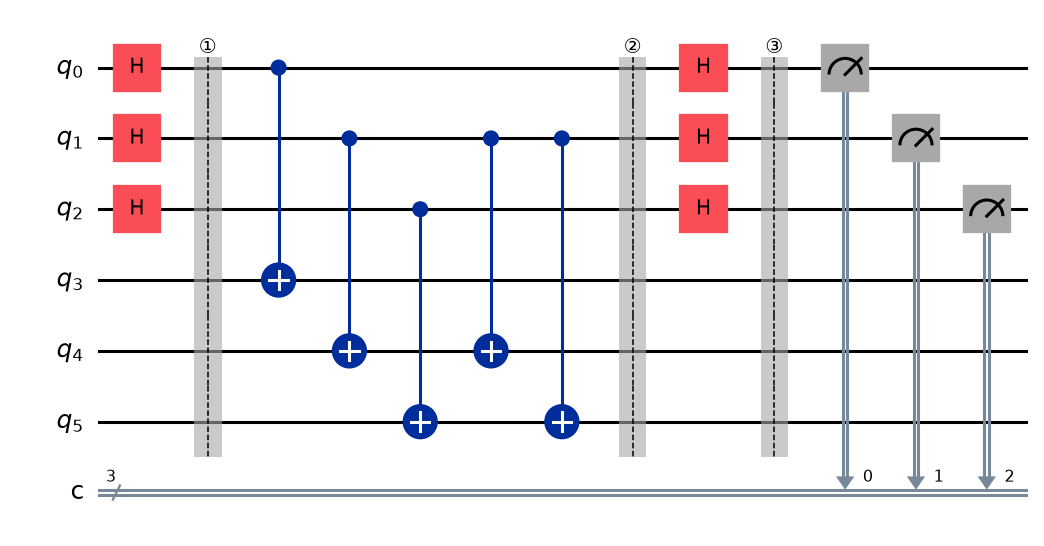

In [9]:
def oraculo_simon(s: str) -> QuantumCircuit:
    """f 2-a-1 con período s: copiar x, y después mezclar según s."""
    n = len(s)
    qc = QuantumCircuit(2 * n, name=f"Simon s={s}")
    for i in range(n):
        qc.cx(i, n + i)                       # f(x) = x  (biyectiva)
    if "1" in s:
        j = s[::-1].index("1")                # bit prendido menos significativo
        for i, b in enumerate(s[::-1]):
            if b == "1":
                qc.cx(j, n + i)               # la vuelve 2-a-1 con período s
    return qc


def simon(s: str) -> QuantumCircuit:
    n = len(s)
    qc = QuantumCircuit(2 * n, n)
    qc.h(range(n))
    marca(qc, 1)
    qc.compose(oraculo_simon(s), range(2 * n), inplace=True)
    marca(qc, 2)
    qc.h(range(n))
    marca(qc, 3)
    qc.measure(range(n), range(n))
    return qc


S_SIMON = "110"
n_s = len(S_SIMON)
display(simon(S_SIMON).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa — dónde ocurre la cancelación

Esta derivación es la más clara de las cuatro, porque se ve **exactamente**
por qué solo sobreviven los $y$ ortogonales a $s$.

**①** Dado que se aplican las $H$ al registro de entrada:
$$|\psi_1\rangle = \frac{1}{\sqrt{2^n}}\sum_{x} |x\rangle\,|0\rangle .$$

**②** Dado que se aplica $U_f$, que escribe $f(x)$ en el registro de salida:
$$|\psi_2\rangle = \frac{1}{\sqrt{2^n}}\sum_{x} |x\rangle\,|f(x)\rangle .$$

Acá hay que **reagrupar**. Como $f$ es dos a uno y $f(x) = f(x \oplus s)$,
los $2^n$ términos se juntan de a pares que comparten la misma salida:

$$|\psi_2\rangle = \frac{1}{\sqrt{2^{n-1}}}\sum_{\text{pares}}
  \left(\frac{|x\rangle + |x \oplus s\rangle}{\sqrt2}\right)
  \otimes |f(x)\rangle .$$

**El registro de entrada quedó en una superposición de pares**, y cada par
está etiquetado por su valor de $f$. Nunca medimos la salida: no hace falta,
y
de hecho es indistinto — lo único que importa es que el entrelazamiento con
la
salida obliga a la entrada a quedarse dentro de un par.

**③** Dado que se aplican las $H$ otra vez sobre la entrada. Usando
$H^{\otimes n}|x\rangle = \frac{1}{\sqrt{2^n}}\sum_y (-1)^{x\cdot
y}|y\rangle$,
cada par se transforma en

$$\frac{|x\rangle + |x\oplus s\rangle}{\sqrt2}
  \;\longrightarrow\;
  \frac{1}{\sqrt{2^{n+1}}}\sum_{y}
  \Big[(-1)^{x\cdot y} + (-1)^{(x\oplus s)\cdot y}\Big]|y\rangle .$$

Y ahora miremos el corchete, que es donde pasa todo. Como
$(x \oplus s)\cdot y = x\cdot y \oplus s\cdot y$:

$$(-1)^{x\cdot y} + (-1)^{x\cdot y}(-1)^{s\cdot y}
 = (-1)^{x\cdot y}\Big[1 + (-1)^{s\cdot y}\Big]
 = \begin{cases}
     2\,(-1)^{x\cdot y} & \text{si } s\cdot y = 0 \\
     \mathbf{0} & \text{si } s\cdot y = 1
   \end{cases}$$

**Los $y$ que no son ortogonales a $s$ se cancelan exactamente.** No es que
sean improbables: su amplitud es cero, por interferencia destructiva entre
los
dos miembros de cada par.

Y el factor $(-1)^{x\cdot y}$ que sobrevive depende de $x$, que no conocemos
— por eso el $y$ que sale es **impredecible** dentro de los
permitidos. El circuito no elige cuál: entrega uno al azar, uniformemente,
entre los $2^{n-1}$ que cumplen $y\cdot s = 0$.

De ahí las dos caras de Simon: **la restricción es determinista** (siempre
$y\cdot s = 0$) pero **cuál restricción toca es aleatorio**, y por eso hacen
falta varias corridas y álgebra lineal para despejar $s$.

comprobación de que el oráculo es realmente 2-a-1 con período s
print(f"\nLa función f, tabulada (s = {S_SIMON}):")
tabla = {}
for x in range(2 ** n_s):
    qc = QuantumCircuit(2 * n_s)
    for i, b in enumerate(format(x, f"0{n_s}b")[::-1]):
        if b == "1":
            qc.x(i)
    qc.compose(oraculo_simon(S_SIMON), range(2 * n_s), inplace=True)
    sv = Statevector(qc)
    idx = int(np.argmax(np.abs(sv.data)))
    fx = format(idx, f"0{2 * n_s}b")[:n_s]
    tabla.setdefault(fx, []).append(format(x, f"0{n_s}b"))
for fx, xs in sorted(tabla.items()):
    xor = format(int(xs[0], 2) ^ int(xs[1], 2), f"0{n_s}b") if len(xs) > 1
      else "-"
    print(f"  f(x) = {fx}  ←  x ∈ {xs}     XOR = {xor}")

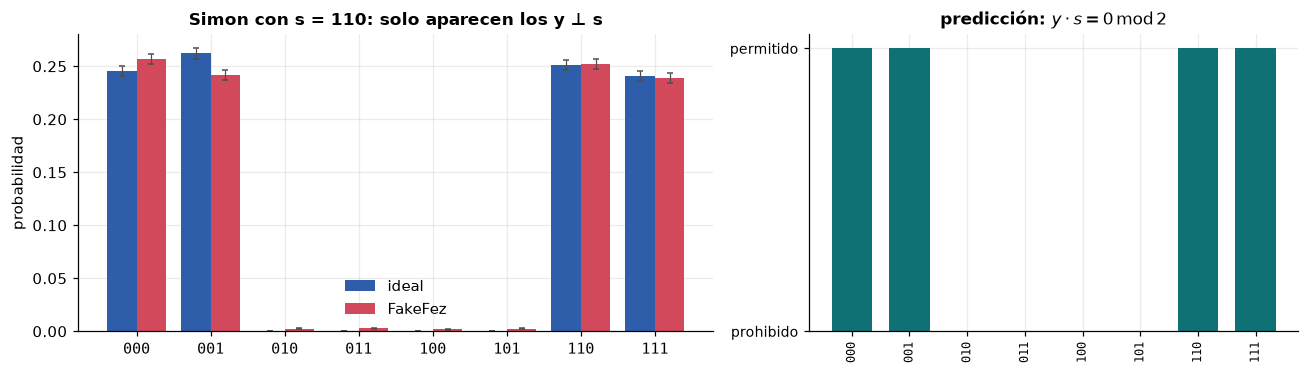

y medidos (ideal): ['000', '001', '110', '111']
y permitidos     : ['000', '001', '110', '111']
¿coinciden? True


In [10]:
c_simon = utils.correr_ideal(simon(S_SIMON), shots=SHOTS)
c_simon_r = utils.correr_ruidoso(simon(S_SIMON), backend_falso=fez, shots=SHOTS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5),
                               gridspec_kw={"width_ratios": [1.3, 1]})
utils.comparar_conteos({"ideal": c_simon, "FakeFez": c_simon_r},
                       claves=utils.claves_completas(n_s), ax=ax1,
                       titulo=f"Simon con s = {S_SIMON}: solo aparecen los y ⊥ s")

validos = [y for y in utils.claves_completas(n_s)
           if sum(int(a) * int(b) for a, b in zip(y, S_SIMON)) % 2 == 0]
ax2.bar(range(2 ** n_s), [1 if y in validos else 0 for y in utils.claves_completas(n_s)],
        color=[utils.COLOR_HARD if y in validos else "0.85"
               for y in utils.claves_completas(n_s)], width=0.7)
ax2.set_xticks(range(2 ** n_s))
ax2.set_xticklabels(utils.claves_completas(n_s), rotation=90, family="monospace",
                    fontsize=8)
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["prohibido", "permitido"], fontsize=9)
ax2.set_title(r"predicción: $y \cdot s = 0 \,\mathrm{mod}\, 2$")
utils.layout(fig)
plt.show()

print(f"y medidos (ideal): {sorted(c_simon)}")
print(f"y permitidos     : {validos}")
print("¿coinciden?", sorted(c_simon) == validos)

## 5.2 El post-proceso: álgebra lineal sobre $\mathbb{F}_2$

Cada $y$ medido es una ecuación $y \cdot s = 0$. Vamos juntando ecuaciones
hasta tener $n-1$ **linealmente independientes**, y ahí el sistema determina
$s$ salvo el vector nulo.

La parte cuántica termina acá: lo que sigue es eliminación gaussiana módulo
2,
y se hace en la laptop.

Recolectando ecuaciones para n = 3 (hacen falta 2):

  medido y = 111   independiente ✓            rango = 1
  medido y = 001   independiente ✓            rango = 2

sistema: ['111', '001']
soluciones no nulas: ['110']
s verdadero        : 110


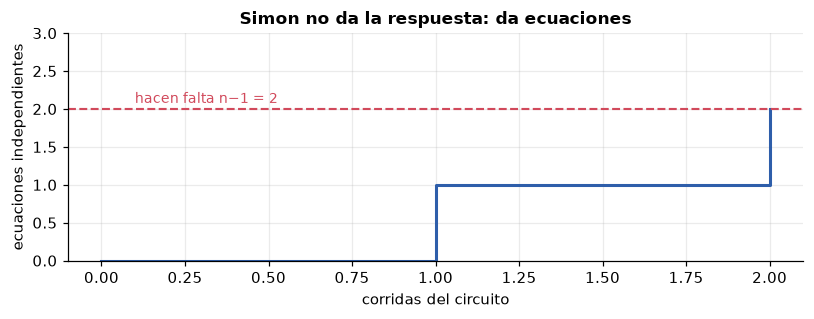

In [11]:
def rango_f2(M: np.ndarray) -> int:
    """Rango de una matriz binaria, por eliminación gaussiana mod 2."""
    M = M.copy() % 2
    filas, cols = M.shape
    r = 0
    for c in range(cols):
        pivote = None
        for i in range(r, filas):
            if M[i, c]:
                pivote = i
                break
        if pivote is None:
            continue
        M[[r, pivote]] = M[[pivote, r]]
        for i in range(filas):
            if i != r and M[i, c]:
                M[i] = (M[i] + M[r]) % 2
        r += 1
    return r


def resolver_simon(ys, n):
    """Devuelve el único s≠0 que satisface y·s=0 para todas las ecuaciones."""
    M = np.array([[int(b) for b in y] for y in ys]) % 2
    candidatos = []
    for cand in itertools.product([0, 1], repeat=n):
        if any(cand) and np.all((M @ np.array(cand)) % 2 == 0):
            candidatos.append("".join(map(str, cand)))
    return candidatos


# Simular la recolección de ecuaciones, una corrida por vez
rng = np.random.default_rng(7)
poblacion = [y for y, v in c_simon.items() for _ in range(v)]
ecuaciones, historial = [], []
while True:
    y = poblacion[rng.integers(len(poblacion))]
    if y == "0" * n_s:
        historial.append((y, "trivial, no aporta", len(ecuaciones)))
        continue
    prueba = ecuaciones + [y]
    M = np.array([[int(b) for b in e] for e in prueba])
    if rango_f2(M) > len(ecuaciones):
        ecuaciones.append(y)
        historial.append((y, "independiente ✓", len(ecuaciones)))
    else:
        historial.append((y, "dependiente, ya la tenía", len(ecuaciones)))
    if len(ecuaciones) == n_s - 1:
        break

print(f"Recolectando ecuaciones para n = {n_s} (hacen falta {n_s - 1}):\n")
for y, estado, rango in historial:
    print(f"  medido y = {y}   {estado:<26} rango = {rango}")
print(f"\nsistema: {ecuaciones}")
print(f"soluciones no nulas: {resolver_simon(ecuaciones, n_s)}")
print(f"s verdadero        : {S_SIMON}")

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.step(range(len(historial) + 1), [0] + [h[2] for h in historial], where="post",
        color=utils.COLOR_IDEAL, lw=2)
ax.axhline(n_s - 1, color=utils.COLOR_RUIDO, ls="--", lw=1.4)
ax.text(0.1, n_s - 0.92, f"hacen falta n−1 = {n_s - 1}", fontsize=9,
        color=utils.COLOR_RUIDO)
ax.set_xlabel("corridas del circuito")
ax.set_ylabel("ecuaciones independientes")
ax.set_ylim(0, n_s)
ax.set_title("Simon no da la respuesta: da ecuaciones")
utils.layout(fig)
plt.show()

**Ahí está la diferencia esencial con Bernstein-Vazirani.** BV devuelve la
respuesta completa en una consulta. Simon devuelve una **restricción al
azar**,
y hay que juntar varias. Algunas corridas no aportan nada —sale el vector
nulo
o una ecuación que ya tenías— y por eso el número esperado de corridas es
un poco mayor que $n-1$, pero sigue siendo $O(n)$.

Ese patrón —**la corrida cuántica devuelve una muestra que restringe la
respuesta, y el post-proceso clásico la despeja**— es exactamente la
estructura de Shor, donde cada corrida da una fracción $s/r$ y las
fracciones continuas despejan $r$. Simon es Shor con XOR en lugar de suma
modular.

---
# 6. Escalado

Cuántas consultas necesita cada uno, en función de $n$.

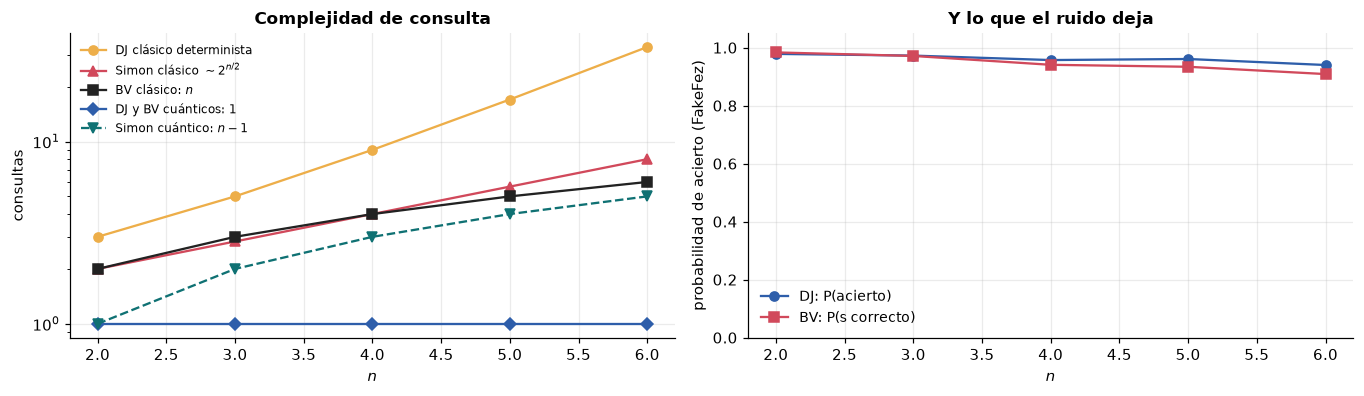

 n   P(DJ)   P(BV)  prof. DJ  prof. BV  prof. Simon
 2   0.979   0.984         7        15           15
 3   0.973   0.971         7        16           15
 4   0.957   0.941         7        29           15
 5   0.961   0.934         7        35           15
 6   0.940   0.909         7        42           15


In [12]:
NS = [2, 3, 4, 5, 6]
fid_dj, fid_bv = [], []
prof_dj, prof_bv, prof_simon = [], [], []
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm_fez = generate_preset_pass_manager(optimization_level=1, backend=fez)
for n in NS:
    s = "1" * n
    cdj = utils.correr_ruidoso(deutsch_jozsa(n, "constante", 0),
                               backend_falso=fez, shots=4096)
    fid_dj.append(cdj.get("0" * n, 0) / 4096)
    cbv = utils.correr_ruidoso(bernstein_vazirani(s), backend_falso=fez, shots=4096)
    fid_bv.append(cbv.get(s, 0) / 4096)
    prof_dj.append(pm_fez.run(deutsch_jozsa(n, "constante", 0)).depth())
    prof_bv.append(pm_fez.run(bernstein_vazirani(s)).depth())
    prof_simon.append(pm_fez.run(simon(("1" + "0" * (n - 2) + "1") if n > 1 else "1")).depth())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.7))
nn = np.array(NS)
ax1.semilogy(nn, 2 ** (nn - 1) + 1, "o-", color=utils.PALETA[3],
             label="DJ clásico determinista")
ax1.semilogy(nn, 2 ** (nn / 2), "^-", color=utils.COLOR_RUIDO,
             label=r"Simon clásico $\sim 2^{n/2}$")
ax1.semilogy(nn, nn, "s-", color=utils.COLOR_TEORIA, label="BV clásico: $n$")
ax1.semilogy(nn, np.ones_like(nn), "D-", color=utils.COLOR_IDEAL,
             label="DJ y BV cuánticos: 1")
ax1.semilogy(nn, nn - 1, "v--", color=utils.COLOR_HARD, label="Simon cuántico: $n-1$")
ax1.set_xlabel("$n$"); ax1.set_ylabel("consultas")
ax1.set_title("Complejidad de consulta")
ax1.legend(fontsize=8)

ax2.plot(NS, fid_dj, "o-", color=utils.COLOR_IDEAL, label="DJ: P(acierto)")
ax2.plot(NS, fid_bv, "s-", color=utils.COLOR_RUIDO, label="BV: P(s correcto)")
ax2.set_xlabel("$n$"); ax2.set_ylabel("probabilidad de acierto (FakeFez)")
ax2.set_ylim(0, 1.05)
ax2.set_title("Y lo que el ruido deja")
ax2.legend(fontsize=9)
utils.layout(fig)
plt.show()

print(f"{'n':>2} {'P(DJ)':>7} {'P(BV)':>7} {'prof. DJ':>9} {'prof. BV':>9} {'prof. Simon':>12}")
for i, n in enumerate(NS):
    print(f"{n:>2} {fid_dj[i]:>7.3f} {fid_bv[i]:>7.3f} {prof_dj[i]:>9} "
          f"{prof_bv[i]:>9} {prof_simon[i]:>12}")

**Bernstein-Vazirani es el más robusto de los tres**, y eso tiene una razón
estructural: su circuito son puras CNOT desde los qubits de entrada hacia un
único auxiliar, así que la profundidad crece poco. De hecho BV se usa como
**benchmark de hardware**: como se sabe la respuesta exacta, la fracción de
shots que la dan mide directamente la calidad del chip.

Simon es el más caro: necesita $2n$ qubits y muchas más compuertas de dos
qubits.

---
# 7. Hardware real

Los tres entran cómodos en NISQ con $n = 3$ o $4$. BV es el mejor candidato.

In [13]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [14]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [15]:
SHOTS_HW = 4096
CASOS_HW = ([("deutsch_const", deutsch("constante_0")),
             ("deutsch_bal", deutsch("balanceada_id"))] +
            [(f"dj_{t}_{s}", deutsch_jozsa(3, t, s)) for t, s in
             [("constante", 0), ("balanceada", 3)]] +
            [(f"bv_{s}", bernstein_vazirani(s)) for s in ("101", "1011", "11011")] +
            [("simon_110", simon("110"))])

t_alg = None
if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_alg = pm.run([c for _, c in CASOS_HW])
    print("=== 8 circuitos en un job ===")
    costo = utils.informe_transpilacion(t_alg, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


In [16]:
ENVIAR_ALGORITMOS = False   # ponerlo en True para gastar QPU

if ENVIAR_ALGORITMOS:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_alg, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"05 Deutsch/DJ/BV/Simon: 8 circuitos, {SHOTS_HW} shots",
                        notebook="05", experimento="oraculos",
                        n_circuitos=len(t_alg), shots=SHOTS_HW,
                        orden=[n for n, _ in CASOS_HW])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [17]:
registros = utils.listar_jobs(filtro="05 ")

In [18]:
JOB_ID = ""   # vacío = el último job de oráculos

if not JOB_ID:
    reg = utils.ultimo_job(experimento="oraculos")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    res = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(res, i) for i in range(len(res))]
    esperados = ["0", "1", "000", None, "101", "1011", "11011", None]

    fig, ejes = plt.subplots(2, 4, figsize=(15.5, 6))
    for ax, (nombre, _), c in zip(ejes.ravel(), CASOS_HW, hw):
        nb = len(next(iter(c)))
        utils.comparar_conteos({"hardware": c}, claves=utils.claves_completas(nb),
                               ax=ax, titulo=nombre)
        ax.set_xlabel("")
    utils.layout(fig)
    plt.show()

    print(f"{'caso':<16} {'esperado':>10} {'obtenido':>10} {'P(esperado)':>12}")
    for (nombre, _), c, esp in zip(CASOS_HW, hw, esperados):
        n_tot = sum(c.values())
        p = f"{c.get(esp, 0) / n_tot:.4f}" if esp else "—"
        print(f"{nombre:<16} {str(esp):>10} {max(c, key=c.get):>10} {p:>12}")

    ys_hw = [y for y in hw[-1] if y != "000"]
    print(f"\nSimon en hardware: y medidos = {sorted(hw[-1], key=hw[-1].get, reverse=True)[:5]}")
    print(f"soluciones compatibles con los 3 más frecuentes: "
          f"{resolver_simon([y for y in sorted(hw[-1], key=hw[-1].get, reverse=True)[:4] if y != '000'][:2], 3)}")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


---
## Qué quedó establecido

1. **El retroceso de fase con el auxiliar en $|-\rangle$** convierte la
salida
   de $f$ en un signo sobre $|x\rangle$, sin tocar el auxiliar. Es el mismo
   mecanismo que en QPE.
2. **La transformada de Hadamard lee patrones de fase.** Constante ⟶
   interferencia constructiva en `00…0`; balanceada ⟶ cancelación exacta.
3. **Deutsch-Jozsa tiene un asterisco**: contra algoritmos clásicos
   aleatorizados la ventaja desaparece. Es una demostración de mecanismo.
4. **Bernstein-Vazirani devuelve $n$ bits en una consulta** con el mismo
   circuito. El oráculo escribe $s$ en las fases y $H^{\otimes n}$ lo lee.
5. **Simon sí tiene separación exponencial real**, incluso contra
   aleatorización. Pero no devuelve la respuesta: devuelve **una ecuación
   lineal al azar**, y hay que juntar $n-1$ independientes.
6. Ese patrón —muestrear una restricción, resolver clásicamente— es la
estructura de Shor.

**Siguiente:** `09_shor_simulador.ipynb`, donde el XOR de Simon se convierte
en aritmética modular y las ecuaciones lineales, en fracciones continuas.